**SETUP AND CONFIGURATION**

In [1]:
!pip install -q transformers datasets accelerate evaluate shap sentencepiece emoji sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 22.7 MB/s eta 0:00:00


In [ ]:
import os, re, io, json, zipfile, collections, gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import emoji
from tqdm.auto import tqdm
tqdm.pandas()
from google.colab import files

# CONFIGURATION
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Menggunakan device:", DEVICE)

TEXT_COLUMN = "text"        # kolom teks komentar asli dari scraper
TEXT_COL = "clean_text"     # kolom teks hasil cleaning

#FOLDER OUTPUT 
RESULTS_DIR = "hasil_revisi"
os.makedirs(RESULTS_DIR, exist_ok=True)

# GOLD SET (BAGIAN B) - TIDAK DIPAKAI
N_GOLD = 600           
MIN_PER_CELL = 20      

# SPLIT (BAGIAN C) - TIDAK DIPAKAI
SPLIT_TEST = 0.10
SPLIT_VAL = 0.10

#MODEL (BAGIAN C)
MAIN_MODEL = ("IndoBERT", "indobenchmark/indobert-base-p1")
EXTRA_MODELS = {"IndoBERTweet": "indolem/indobertweet-base-uncased"}   
SEEDS_MAIN = [42, 43, 44]     
SEEDS_EXTRA = [42]

# SHAP (Bagian D)
N_SHAP_PER_CLASS = 100        # komentar per kelas prediksi
MIN_TOKEN_FREQ = 5            # token harus muncul di >= N komentar agar masuk ranking
FILTER_ENGLISH = True         # buang kata Inggris umum (don, my, but, ...) dari ranking token

TASKS = {"aspek": "aspek_prediksi", "sentimen": "sentimen_prediksi"}
CANONICAL_LABELS = {
    "aspek": ["Aspek Lingkungan Keluarga", "Aspek Tekanan Sosial & Media", "Aspek Beban Kerja & Akademik"],
    "sentimen": ["Positif", "Negatif", "Netral"],
}


#HELPER FUNCTIONS
def upload_one(prompt):
    print(prompt)
    up = files.upload()
    name = list(up.keys())[0]
    return name, up[name]


def read_csv_flex(content, must_have):
    """Baca CSV (separator koma atau titik koma, encoding utf-8 atau latin-1). must_have = kolom wajib."""
    last = None
    for enc in ["utf-8-sig", "latin-1"]:
        for sep in [",", ";"]:
            try:
                d = pd.read_csv(io.BytesIO(content), sep=sep, encoding=enc, on_bad_lines="skip")
                if all(c in d.columns for c in must_have):
                    return d
            except Exception as e:
                last = e
    raise ValueError(f"Kolom {must_have} tidak ditemukan. Cek separator dan nama kolom. {last or ''}")

Menggunakan device: cuda


**MERGE, DEDUP, PREPROCESSING, HYBRID LABELLING**

In [ ]:
# A.1 Upload seluruh file CSV hasil scraping semua
uploaded_all = files.upload()
print("Jumlah file terupload:", len(uploaded_all))
for fname in uploaded_all.keys():
    print("-", fname)

list_df = []
for fname, content in uploaded_all.items():
    try:
        temp_df = pd.read_csv(io.BytesIO(content))
    except UnicodeDecodeError:
        temp_df = pd.read_csv(io.BytesIO(content), encoding="latin-1")
    temp_df["source_file"] = fname   # lacak asal file
    list_df.append(temp_df)
    print(f"{fname}: {temp_df.shape[0]} baris, {temp_df.shape[1]} kolom")

df = pd.concat(list_df, axis=0, ignore_index=True, sort=False)
print("\nTotal baris sebelum dedup:", len(df))
print("Kolom hasil gabungan:", df.columns.tolist())

Saving dataset_tiktok-comments-1.csv to dataset_tiktok-comments-1.csv
Saving dataset_tiktok-comments-2.csv to dataset_tiktok-comments-2.csv
Saving dataset_tiktok-comments-3.csv to dataset_tiktok-comments-3.csv
Saving dataset_tiktok-comments-4.csv to dataset_tiktok-comments-4.csv
Saving dataset_tiktok-comments-5.csv to dataset_tiktok-comments-5.csv
Saving dataset_tiktok-comments-6.csv to dataset_tiktok-comments-6.csv
Saving dataset_tiktok-comments-7.csv to dataset_tiktok-comments-7.csv
Saving dataset_tiktok-comments-8.csv to dataset_tiktok-comments-8.csv
Saving dataset_tiktok-comments-9.csv to dataset_tiktok-comments-9.csv
Saving dataset_tiktok-comments-10.csv to dataset_tiktok-comments-10.csv
Saving dataset_tiktok-comments-11.csv to dataset_tiktok-comments-11.csv
Saving dataset_tiktok-comments-12.csv to dataset_tiktok-comments-12.csv
Saving dataset_tiktok-comments-13.csv to dataset_tiktok-comments-13.csv
Saving dataset_tiktok-comments-14.csv to dataset_tiktok-comments-14.csv
Saving dat

In [ ]:
# A.2 Deduplication
print("Kolom yang tersedia:", df.columns.tolist())
print("Jumlah baris sebelum dedup:", len(df))
before = len(df)

if "uniqueId" in df.columns and df["uniqueId"].notna().any():
    df = df.drop_duplicates(subset=["uniqueId"], keep="first").reset_index(drop=True)
    dedup_method = "uniqueId"
else:
    subset_cols = [TEXT_COLUMN]
    if "submittedVideoUrl" in df.columns:
        subset_cols.append("submittedVideoUrl")
    df = df.drop_duplicates(subset=subset_cols, keep="first").reset_index(drop=True)
    dedup_method = f"kombinasi kolom {subset_cols}"

df = df[df[TEXT_COLUMN].notna()].reset_index(drop=True)
after = len(df)
print(f"Metode dedup yang digunakan: {dedup_method}")
print(f"Baris duplikat/kosong terhapus: {before - after}")
print(f"Total baris final gabungan: {after}")

df.to_csv("newdataset_scraping_merged.csv", index=False)
print("Tersimpan: newdataset_scraping_merged.csv")

Kolom yang tersedia: ['uniqueId', 'submittedVideoUrl', 'text', 'source_file']
Jumlah baris sebelum dedup: 9047
Metode dedup yang digunakan: uniqueId
Baris duplikat/kosong terhapus: 207
Total baris final gabungan: 8840
Tersimpan: newdataset_scraping_merged.csv


In [ ]:
# A.3 Preprocessing
slang_dict = {
    "gws": "semoga cepat sembuh", "gabut": "tidak ada kegiatan", "capek": "lelah", "cape": "lelah",
    "burnout": "kelelahan mental", "bgt": "banget", "banget": "sangat", "gk": "tidak", "ga": "tidak",
    "gak": "tidak", "nggak": "tidak", "ngga": "tidak", "yg": "yang", "krn": "karena", "karna": "karena",
    "sm": "sama", "dr": "dari", "utk": "untuk", "jd": "jadi", "jgn": "jangan", "udh": "sudah",
    "udah": "sudah", "blm": "belum", "aja": "saja", "aj": "saja", "trs": "terus", "dgn": "dengan",
    "org": "orang", "tp": "tapi", "tapi": "tetapi", "skrg": "sekarang", "sy": "saya", "gue": "saya",
    "gw": "saya", "lu": "kamu", "lo": "kamu", "wlyd": "worklife balance", "wlb": "worklife balance",
    "wfh": "kerja dari rumah", "wfo": "kerja dari kantor", "deadline": "tenggat waktu",
    "dl": "tenggat waktu", "healing": "menenangkan diri", "insecure": "tidak percaya diri",
    "overthinking": "terlalu banyak berpikir", "circle": "lingkungan pertemanan", "julid": "mencibir",
    "toxic": "beracun", "japri": "pesan pribadi", "japrian": "pesan pribadi", "santuy": "santai",
    "santai": "tenang", "kzl": "kesal", "bete": "kesal", "mager": "malas gerak", "japan": "jarang panik",
}


def normalize_slang(text, slang_map=slang_dict):
    """Mengganti kata slang/singkatan menjadi bentuk baku berdasarkan kamus."""
    words = text.split()
    normalized = [slang_map.get(w, w) for w in words]
    return " ".join(normalized)


def clean_tiktok_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # URL
    text = re.sub(r"@\w+", " ", text)                   # mention
    text = re.sub(r"#\w+", " ", text)                   # hashtag
    text = emoji.replace_emoji(text, replace=" ")       # emoji
    text = re.sub(r"\d+", " ", text)                    # angka
    text = normalize_slang(text)                        # slang
    text = re.sub(r"[^a-zA-Z\s]", " ", text)            # tanda baca / non-alfabet
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["clean_text"] = df[TEXT_COLUMN].progress_apply(clean_tiktok_text)
df = df[df["clean_text"].str.split().str.len() >= 2].reset_index(drop=True)
print("Jumlah baris setelah cleaning:", len(df))
df.to_csv("newdataset_preprocessing_cleaned.csv", index=False)
print("Tersimpan: newdataset_preprocessing_cleaned.csv")

  0%|          | 0/8840 [00:00<?, ?it/s]

Jumlah baris setelah cleaning: 7199
Tersimpan: newdataset_preprocessing_cleaned.csv


In [ ]:
# A.4 Statistik pengumpulan data
per_file = df.groupby("source_file").size().rename("jumlah_komentar").reset_index()
print("Komentar per file/video (setelah preprocessing):")
print(per_file.to_string(index=False))
print("\nRingkasan: min/median/maks komentar per video =",
      per_file["jumlah_komentar"].min(), "/", per_file["jumlah_komentar"].median(), "/", per_file["jumlah_komentar"].max())
if "submittedVideoUrl" in df.columns:
    print("Jumlah URL video unik:", df["submittedVideoUrl"].nunique())

for c in [c for c in df.columns if "createtime" in c.lower()]:
    s = df[c]
    dt = pd.to_datetime(s, unit="s", errors="coerce") if pd.api.types.is_numeric_dtype(s) else pd.to_datetime(s, errors="coerce")
    print(f"Rentang waktu komentar ({c}): {dt.min()}  s.d.  {dt.max()}")

per_file.to_csv(f"{RESULTS_DIR}/statistik_komentar_per_video.csv", index=False)

Komentar per file/video (setelah preprocessing):
                   source_file  jumlah_komentar
 dataset_tiktok-comments-1.csv             1126
dataset_tiktok-comments-10.csv              129
dataset_tiktok-comments-11.csv              100
dataset_tiktok-comments-12.csv               73
dataset_tiktok-comments-13.csv               20
dataset_tiktok-comments-14.csv               30
dataset_tiktok-comments-15.csv               31
dataset_tiktok-comments-16.csv               10
dataset_tiktok-comments-17.csv              268
dataset_tiktok-comments-18.csv              150
dataset_tiktok-comments-19.csv              687
 dataset_tiktok-comments-2.csv              795
dataset_tiktok-comments-20.csv              952
dataset_tiktok-comments-21.csv              964
 dataset_tiktok-comments-3.csv              509
 dataset_tiktok-comments-4.csv              451
 dataset_tiktok-comments-5.csv              370
 dataset_tiktok-comments-6.csv              157
 dataset_tiktok-comments-7.csv         

In [ ]:
# A.5 Pelabelan hybrid: rule-based dulu, fallback zero-shot
from transformers import pipeline

ASPECT_KEYWORDS = {
    "Aspek Lingkungan Keluarga": [
        "ortu", "orang tua", "orangtua", "ayah", "ibu", "bapak", "mama", "papa",
        "keluarga", "kakak", "adik", "anak", "rumah", "dirumah", "di rumah",
        "dituntut", "ekspektasi keluarga", "broken home", "beban keluarga",
        "anak pertama", "sandwich generation", "tulang punggung",
    ],
    "Aspek Tekanan Sosial & Media": [
        "circle", "pertemanan", "teman", "julid", "toxic", "insecure",
        "bandingin", "dibanding", "standar", "sosial", "medsos", "media sosial",
        "sosmed", "fyp", "komen", "netizen", "fomo", "red flag", "diomongin",
        "digosipin", "trend", "gengsi", "omongan orang", "validasi",
    ],
    "Aspek Beban Kerja & Akademik": [
        "kerja", "kerjaan", "kantor", "deadline", "lembur", "overtime", "kuliah",
        "tugas", "skripsi", "ujian", "dosen", "boss", "bos", "atasan", "gaji",
        "wfh", "wfo", "resign", "magang", "kampus", "sekolah", "task",
        "ptn", "sbmptn", "utbk", "ambisi", "nilai", "jurusan", "karir", "duit",
        "pengangguran", "loker", "interview", "hrd",
    ],
}
SENTIMENT_KEYWORDS = {
    "Negatif": [
        "nangis", "lelah", "takut", "sakit", "gila", "sedih", "berat",
        "marah", "hancur", "kecewa", "pusing", "nyerah", "capek", "cape",
        "stres", "stress", "depresi", "hancur", "beban", "insecure", "overthinking",
        "gak sanggup", "pengen mati", "nyiksa", "toxic", "benci", "malas", "mager",
    ],
    "Positif": [
        "semangat", "baik", "kuat", "alhamdulillah", "bahagia", "bantu",
        "aman", "senang", "syukur", "bersyukur", "keren", "proud", "bangga",
        "healing", "solusi", "dukung", "support", "terbantu", "paham", "bagus",
        "seimbang", "wlb",
    ],
    "Netral": [
        "info", "tanya", "nanya", "artinya", "maksudnya", "apa itu", "bedanya",
        "gimana", "bagaimana", "berita", "artikel", "menurut", "fakta", "contoh", "penelitian",
    ],
}
aspect_labels = list(ASPECT_KEYWORDS.keys())
sentiment_labels = list(SENTIMENT_KEYWORDS.keys())
ASPECT_HYPOTHESIS_TEMPLATE = "Komentar ini membahas tentang tekanan dari {}."
SENTIMENT_HYPOTHESIS_TEMPLATE = "Emosi dari komentar ini adalah {}."


def rule_based_match(text: str, keyword_map: dict):
    scores = {}
    text_lower = str(text).lower()
    for label, keywords in keyword_map.items():
        count = sum(1 for kw in keywords if re.search(rf"\b{re.escape(kw)}\b", text_lower))
        if count > 0:
            scores[label] = count
    if not scores:
        return None, 0
    best_label = max(scores, key=scores.get)
    return best_label, scores[best_label]


print("Memuat model Zero-Shot, harap tunggu...")
zero_shot = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=0 if DEVICE == "cuda" else -1,
)
print("Model Zero-Shot berhasil dimuat!")


def label_aspect_sentiment(text: str):
    if not text or len(str(text).split()) < 2:
        return "Tidak Diketahui", 0.0, "rule_based", "Netral", 0.0, "rule_based"

    aspek_rule, _ = rule_based_match(text, ASPECT_KEYWORDS)
    if aspek_rule is not None:
        top_aspect, top_aspect_score, aspect_method = aspek_rule, 1.0, "rule_based"
    else:
        aspect_result = zero_shot(text, candidate_labels=aspect_labels, hypothesis_template=ASPECT_HYPOTHESIS_TEMPLATE)
        top_aspect = aspect_result["labels"][0]
        top_aspect_score = aspect_result["scores"][0]
        aspect_method = "zero_shot"

    sentimen_rule, _ = rule_based_match(text, SENTIMENT_KEYWORDS)
    if sentimen_rule is not None:
        top_sentiment, top_sentiment_score, sentiment_method = sentimen_rule, 1.0, "rule_based"
    else:
        sentiment_result = zero_shot(text, candidate_labels=sentiment_labels, hypothesis_template=SENTIMENT_HYPOTHESIS_TEMPLATE)
        top_sentiment = sentiment_result["labels"][0]
        top_sentiment_score = sentiment_result["scores"][0]
        sentiment_method = "zero_shot"

    return top_aspect, top_aspect_score, aspect_method, top_sentiment, top_sentiment_score, sentiment_method

Memuat model Zero-Shot, harap tunggu...


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Model Zero-Shot berhasil dimuat!


In [ ]:
# A.6 Labeling Execution
results = df["clean_text"].progress_apply(lambda t: pd.Series(label_aspect_sentiment(t)))
results.columns = ["aspek_prediksi", "skor_aspek", "aspek_metode",
                   "sentimen_prediksi", "skor_sentimen", "sentimen_metode"]
df_labeled = pd.concat([df, results], axis=1)

print("Distribusi Aspek:\n", df_labeled["aspek_prediksi"].value_counts())
print("\nDistribusi Sentimen:\n", df_labeled["sentimen_prediksi"].value_counts())
print("\nMetode Aspek:\n", df_labeled["aspek_metode"].value_counts())
print("\nMetode Sentimen:\n", df_labeled["sentimen_metode"].value_counts())

df_labeled.to_csv("hybrid_labeled_dataset.csv", index=False)
print("\nTersimpan: hybrid_labeled_dataset.csv")

  0%|          | 0/7199 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Distribusi Aspek:
 aspek_prediksi
Aspek Tekanan Sosial & Media    3580
Aspek Lingkungan Keluarga       1997
Aspek Beban Kerja & Akademik    1622
Name: count, dtype: int64

Distribusi Sentimen:
 sentimen_prediksi
Netral     3191
Negatif    2745
Positif    1263
Name: count, dtype: int64

Metode Aspek:
 aspek_metode
zero_shot     4554
rule_based    2645
Name: count, dtype: int64

Metode Sentimen:
 sentimen_metode
zero_shot     4747
rule_based    2452
Name: count, dtype: int64

Tersimpan: hybrid_labeled_dataset.csv


**VALIDASI DATA**

In [ ]:
# B.0 Siapkan df_hybrid dan df_main 
ASPEK_CODE = {"KEL": "Aspek Lingkungan Keluarga", "SOS": "Aspek Tekanan Sosial & Media", "KER": "Aspek Beban Kerja & Akademik"}
SENT_CODE = {"POS": "Positif", "NEG": "Negatif", "NET": "Netral"}
APPLY_OLD_NEUTRAL_VALIDATION = True   

if "df_labeled" in globals():
    df_hybrid = df_labeled.copy()
else:
    _, content = upload_one("Upload hybrid_labeled_dataset.csv")
    df_hybrid = read_csv_flex(content, ["uniqueId", "clean_text", "aspek_prediksi", "sentimen_prediksi", "aspek_metode", "sentimen_metode"])
if TEXT_COLUMN not in df_hybrid.columns:
    raise ValueError(f"Kolom teks asli '{TEXT_COLUMN}' tidak ada di dataset; sesuaikan TEXT_COLUMN di konfigurasi.")
assert df_hybrid["uniqueId"].is_unique, "uniqueId tidak unik, pakai kolom ID lain sebagai kunci."

df_main = df_hybrid.copy()
df_main["aspek_sumber"] = df_main["aspek_metode"]
df_main["sentimen_sumber"] = df_main["sentimen_metode"]

if APPLY_OLD_NEUTRAL_VALIDATION:
    _, content = upload_one("Upload sample_aftervalidasi_netral.csv (validasi manual 300 komentar Neutral yang sudah kamu kerjakan)")
    df_old_val = read_csv_flex(content, ["uniqueId", "aspek_prediksi", "sentimen_prediksi"])
    df_old_val["aspek_prediksi"] = df_old_val["aspek_prediksi"].replace(
        "Aspek Tenanan Sosial & Media", "Aspek Tekanan Sosial & Media")
    old_ids = set(df_old_val["uniqueId"])
    df_main = df_main.set_index("uniqueId")
    df_old_val = df_old_val.set_index("uniqueId")
    df_main.update(df_old_val[["aspek_prediksi", "sentimen_prediksi"]])
    df_main = df_main.reset_index()
    df_main.loc[df_main["uniqueId"].isin(old_ids), ["aspek_sumber", "sentimen_sumber"]] = "manual_netral"
    print("Validasi Neutral lama diterapkan pada", len(old_ids), "komentar.")
print("Siap. Jumlah baris:", len(df_main))

Upload hybrid_labeled_dataset.csv


Saving hybrid_labeled_dataset.csv to hybrid_labeled_dataset.csv
Upload sample_aftervalidasi_netral.csv (validasi manual 300 komentar Neutral yang sudah kamu kerjakan)


Saving sample_aftervalidasi_netral.csv to sample_aftervalidasi_netral.csv
Validasi Neutral lama diterapkan pada 300 komentar.
Siap. Jumlah baris: 7199


In [ ]:
# B.1 Ekspor lembar anotasi BUTA (tanpa label otomatis)
N_GOLD = 500           # jumlah komentar yang aku anotasi sendiri 
N_SECOND = 150         # subset untuk annotator kedua 
MIN_PER_CELL = 20      # minimal komentar per sel aspek x sentimen


def stratified_gold(d, n_total, min_per_cell, seed):
    d = d[(d["aspek_prediksi"] != "Tidak Diketahui") & d["sentimen_prediksi"].notna()].copy()
    d["cell"] = d["aspek_prediksi"] + "__" + d["sentimen_prediksi"]
    sizes = d["cell"].value_counts()
    alloc = (sizes / sizes.sum() * n_total).round().astype(int).clip(lower=min_per_cell)
    alloc = np.minimum(alloc, sizes)
    parts = [g.sample(n=int(alloc[c]), random_state=seed) for c, g in d.groupby("cell")]
    return pd.concat(parts).drop(columns="cell")


def anonymize(t):
    return re.sub(r"@\w+", "@user", str(t))


import hashlib
ID_SALT = "ID_SALT"   #not for public


def anon_id(u):
    return "c" + hashlib.sha256((ID_SALT + str(u)).encode()).hexdigest()[:10]


gold_sample = stratified_gold(df_hybrid, N_GOLD, MIN_PER_CELL, SEED)
print("Ukuran gold set:", len(gold_sample))
print(pd.crosstab(gold_sample["aspek_prediksi"], gold_sample["sentimen_prediksi"]))

sheet = pd.DataFrame({
    "id_anonim": [anon_id(u) for u in gold_sample["uniqueId"]],   # username TIDAK ikut ke annotator
    "teks": gold_sample[TEXT_COLUMN].map(anonymize).values,   # teks asli (mention dianonimkan)
    "aspek_annotator": "", "sentimen_annotator": "", "multi_aspek": "", "tidak_jelas": "",
})
# urutan diacak, supaya urutan baris tidak membocorkan label otomatis (gold_sample tersusun per kelompok label)
sheet = sheet.sample(frac=1, random_state=SEED + 1).reset_index(drop=True)
sheet.to_csv("gold_annotator1.csv", index=False, encoding="utf-8-sig")
if N_SECOND > 0:
    sheet.sample(n=min(N_SECOND, len(sheet)), random_state=SEED + 2).to_csv(
        "gold_annotator2.csv", index=False, encoding="utf-8-sig")

key = gold_sample[["uniqueId", "aspek_prediksi", "sentimen_prediksi", "aspek_metode", "sentimen_metode"]].copy()
key.insert(0, "id_anonim", [anon_id(u) for u in key["uniqueId"]])
key.to_csv(f"{RESULTS_DIR}/gold_kunci_label_otomatis.csv", index=False)   # JANGAN dibagikan ke annotator

files.download("gold_annotator1.csv")
if N_SECOND > 0:
    files.download("gold_annotator2.csv")
print("\nLembar anotasi memakai id_anonim (bukan username).")
print(f"gold_annotator1.csv = {len(sheet)} komentar untuk KAMU label sendiri.")
if N_SECOND > 0:
    print(f"gold_annotator2.csv = {min(N_SECOND, len(sheet))} komentar (subset acak yang sama) untuk annotator kedua / kamu label ulang >= 2 hari lagi.")
print("Jangan lihat label otomatis saat menganotasi, dan jangan melihat label annotator pertama saat menjadi annotator kedua.")
print("Kode aspek:", ASPEK_CODE)
print("Kode sentimen:", SENT_CODE)

Ukuran gold set: 501
sentimen_prediksi             Negatif  Netral  Positif
aspek_prediksi                                        
Aspek Beban Kerja & Akademik       43      43       27
Aspek Lingkungan Keluarga          67      52       20
Aspek Tekanan Sosial & Media       81     127       41


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Lembar anotasi memakai id_anonim (bukan username).
gold_annotator1.csv = 501 komentar untuk KAMU label sendiri.
gold_annotator2.csv = 150 komentar (subset acak yang sama) untuk annotator kedua / kamu label ulang >= 2 hari lagi.
Jangan lihat label otomatis saat menganotasi, dan jangan melihat label annotator pertama saat menjadi annotator kedua.
Kode aspek: {'KEL': 'Aspek Lingkungan Keluarga', 'SOS': 'Aspek Tekanan Sosial & Media', 'KER': 'Aspek Beban Kerja & Akademik'}
Kode sentimen: {'POS': 'Positif', 'NEG': 'Negatif', 'NET': 'Netral'}


In [ ]:
# B.2 Hitung kesepakatan (Cohen's kappa) pada subset yang dilabeli dua kali, dan ekspor
from sklearn.metrics import cohen_kappa_score

import hashlib
ID_SALT = "ID_SALT"   #NOT FOR PUBLIC


def anon_id(u):
    return "c" + hashlib.sha256((ID_SALT + str(u)).encode()).hexdigest()[:10]


HAS_SECOND = True   
need_cols = ["id_anonim", "teks", "aspek_annotator", "sentimen_annotator"]
_, c1 = upload_one("Upload gold_annotator1.csv yang SUDAH KAMU ISI (semua komentar)")
a1 = read_csv_flex(c1, need_cols)
if HAS_SECOND:
    _, c2 = upload_one("Upload gold_annotator2.csv yang SUDAH DIISI annotator kedua (subset komentar)")
    a2 = read_csv_flex(c2, need_cols)
else:
    a2 = a1.iloc[0:0].copy()


def tidy(a):
    a = a.copy()
    for col in ["aspek_annotator", "sentimen_annotator"]:
        a[col] = a[col].astype(str).str.strip().str.upper().replace({"NAN": ""})
    for col in ["multi_aspek", "tidak_jelas"]:
        if col not in a.columns:
            a[col] = 0
        a[col] = pd.to_numeric(a[col], errors="coerce").fillna(0).astype(int)
    a.loc[~a["aspek_annotator"].isin(ASPEK_CODE), "aspek_annotator"] = ""
    a.loc[~a["sentimen_annotator"].isin(SENT_CODE), "sentimen_annotator"] = ""
    return a


a1, a2 = tidy(a1), tidy(a2)
m = a1.merge(a2.drop(columns=["teks"]), on="id_anonim", how="left", suffixes=("_1", "_2"))
for c in ["aspek_annotator_2", "sentimen_annotator_2"]:
    m[c] = m[c].fillna("")
for c in ["multi_aspek_2", "tidak_jelas_2"]:
    m[c] = m[c].fillna(0).astype(int)
has2 = (m["aspek_annotator_2"] != "") | (m["sentimen_annotator_2"] != "")
print(f"Komentar di lembar utama: {len(m)} | juga dilabeli annotator kedua: {int(has2.sum())}")
id_map = {anon_id(u): u for u in df_hybrid["uniqueId"]}      # petakan balik ke uniqueId
m["uniqueId"] = m["id_anonim"].map(id_map)
assert m["uniqueId"].notna().all(), "Ada id_anonim yang tidak cocok: pastikan ID_SALT sama dengan saat B.1 dan df_hybrid benar."

unclear = (m["tidak_jelas_1"] == 1) | (m["tidak_jelas_2"] == 1)
print("Ditandai tidak_jelas oleh salah satu annotator:", int(unclear.sum()), "(dikeluarkan dari gold)")
multi = ((m["multi_aspek_1"] == 1) | (m["multi_aspek_2"] == 1))
print(f"Ditandai multi_aspek oleh salah satu annotator: {int(multi.sum())} ({multi.mean()*100:.1f}%)  -> laporkan di Limitations (A7)")

agree_rows = []
for task, col in [("aspek", "aspek_annotator"), ("sentimen", "sentimen_annotator")]:
    ok = m[~unclear & (m[col + "_1"] != "") & (m[col + "_2"] != "")]
    if len(ok) < 2:
        continue
    kappa = cohen_kappa_score(ok[col + "_1"], ok[col + "_2"])
    raw = (ok[col + "_1"] == ok[col + "_2"]).mean()
    agree_rows.append({"task": task, "n": len(ok), "percent_agreement": round(raw, 4), "cohen_kappa": round(kappa, 4)})
agree = pd.DataFrame(agree_rows)
if len(agree) == 0:
    print("\nTidak ada komentar yang dilabeli dua kali: kappa TIDAK dihitung. Laporkan sebagai anotasi tunggal dan catat di Limitations.")
else:
    print("\nKesepakatan pada subset yang dilabeli dua kali:\n", agree.to_string(index=False))
    print("(Jika label kedua dibuat oleh kamu sendiri setelah >= 2 hari, laporkan sebagai intra-annotator agreement.)")
agree.to_csv(f"{RESULTS_DIR}/gold_inter_annotator_agreement.csv", index=False)

# tanpa label kedua -> pakai label utama; ada label kedua -> dipakai jika sepakat, selain itu masuk daftar konflik
m["aspek_final"] = np.where(m["aspek_annotator_2"] == "", m["aspek_annotator_1"],
                            np.where(m["aspek_annotator_1"] == m["aspek_annotator_2"], m["aspek_annotator_1"], ""))
m["sentimen_final"] = np.where(m["sentimen_annotator_2"] == "", m["sentimen_annotator_1"],
                               np.where(m["sentimen_annotator_1"] == m["sentimen_annotator_2"], m["sentimen_annotator_1"], ""))
gold_merged = m
conflicts = m[~unclear & ((m["aspek_final"] == "") | (m["sentimen_final"] == ""))]
print("\nKomentar dengan konflik/kosong yang perlu diselesaikan:", len(conflicts))
if len(conflicts) > 0:
    conflicts[["id_anonim", "teks", "aspek_annotator_1", "aspek_annotator_2", "aspek_final",
               "sentimen_annotator_1", "sentimen_annotator_2", "sentimen_final"]].to_csv(
        "gold_konflik.csv", index=False, encoding="utf-8-sig")
    files.download("gold_konflik.csv")
    print("Isi kolom aspek_final / sentimen_final (kode KEL/SOS/KER dan POS/NEG/NET). Putuskan dengan membaca ulang komentar dan "
          "pedoman (atau minta orang ketiga jika ada), lalu upload di B.3.")

Upload gold_annotator1.csv yang SUDAH KAMU ISI (semua komentar)


Saving gold_annotator1_terisi.csv to gold_annotator1_terisi.csv
Upload gold_annotator2.csv yang SUDAH DIISI annotator kedua (subset komentar)


Saving gold_annotator2_terisi.csv to gold_annotator2_terisi.csv
Komentar di lembar utama: 501 | juga dilabeli annotator kedua: 141
Ditandai tidak_jelas oleh salah satu annotator: 46 (dikeluarkan dari gold)
Ditandai multi_aspek oleh salah satu annotator: 0 (0.0%)  -> laporkan di Limitations (A7)

Kesepakatan pada subset yang dilabeli dua kali:
     task   n  percent_agreement  cohen_kappa
   aspek 133             0.8571       0.7852
sentimen 132             0.9318       0.6075
(Jika label kedua dibuat oleh kamu sendiri setelah >= 2 hari, laporkan sebagai intra-annotator agreement.)

Komentar dengan konflik/kosong yang perlu diselesaikan: 27


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Isi kolom aspek_final / sentimen_final (kode KEL/SOS/KER dan POS/NEG/NET). Putuskan dengan membaca ulang komentar dan pedoman (atau minta orang ketiga jika ada), lalu upload di B.3.


In [ ]:
# B.3 Selesaikan konflik -> gold final
if len(conflicts) > 0:
    _, cr = upload_one("Upload gold_konflik.csv yang kolom *_final-nya sudah diisi")
    res = read_csv_flex(cr, ["id_anonim", "aspek_final", "sentimen_final"])
    for col in ["aspek_final", "sentimen_final"]:
        res[col] = res[col].astype(str).str.strip().str.upper().replace({"NAN": ""})
    res = res.set_index("id_anonim")
    gm = gold_merged.set_index("id_anonim")
    for col in ["aspek_final", "sentimen_final"]:
        filled = res[col][res[col] != ""]
        gm.loc[filled.index.intersection(gm.index), col] = filled
    gold_merged = gm.reset_index()

gold = gold_merged[~((gold_merged["tidak_jelas_1"] == 1) | (gold_merged["tidak_jelas_2"] == 1))].copy()
gold = gold[gold["aspek_final"].isin(ASPEK_CODE) & gold["sentimen_final"].isin(SENT_CODE)]
gold["aspek_gold"] = gold["aspek_final"].map(ASPEK_CODE)
gold["sentimen_gold"] = gold["sentimen_final"].map(SENT_CODE)
gold[["uniqueId", "aspek_gold", "sentimen_gold"]].to_csv(f"{RESULTS_DIR}/gold_final.csv", index=False)
print("Gold set final:", len(gold), "komentar")
print(gold["aspek_gold"].value_counts(), "\n", gold["sentimen_gold"].value_counts())

Upload gold_konflik.csv yang kolom *_final-nya sudah diisi


Saving gold_konflik.csv to gold_konflik (2).csv
Gold set final: 455 komentar
aspek_gold
Aspek Lingkungan Keluarga       175
Aspek Beban Kerja & Akademik    162
Aspek Tekanan Sosial & Media    118
Name: count, dtype: int64 
 sentimen_gold
Negatif    380
Positif     66
Netral       9
Name: count, dtype: int64


In [ ]:
# B.4 Seberapa akurat label otomatis (rule-based + zero-shot) terhadap gold set?
from sklearn.metrics import accuracy_score, f1_score

auto = df_hybrid[["uniqueId", "aspek_prediksi", "sentimen_prediksi", "aspek_metode", "sentimen_metode"]]
g = gold[["uniqueId", "aspek_gold", "sentimen_gold"]].merge(auto, on="uniqueId", how="inner")

# Gold set diambil stratified menurut label otomatis, jadi akurasi mentahnya bukan estimasi untuk seluruh data.
# Bobot per sel = (jumlah populasi sel) / (jumlah sampel sel) memberi estimasi untuk populasi (kolom accuracy_weighted).
pop_cell = (auto["aspek_prediksi"] + "__" + auto["sentimen_prediksi"]).value_counts()
g["cell"] = g["aspek_prediksi"] + "__" + g["sentimen_prediksi"]
g["w"] = g["cell"].map(pop_cell) / g["cell"].map(g["cell"].value_counts())

rows = []
for task, gcol, pcol, mcol in [("aspek", "aspek_gold", "aspek_prediksi", "aspek_metode"),
                               ("sentimen", "sentimen_gold", "sentimen_prediksi", "sentimen_metode")]:
    for subset, d in [("semua", g)] + [(mt, g[g[mcol] == mt]) for mt in ["rule_based", "zero_shot"]]:
        if len(d) < 2:
            continue
        rows.append({"task": task, "subset": subset, "n": len(d),
                     "accuracy": round(accuracy_score(d[gcol], d[pcol]), 4),
                     "accuracy_weighted": (round(accuracy_score(d[gcol], d[pcol], sample_weight=d["w"]), 4)
                                           if subset == "semua" else np.nan),
                     "macro_f1": round(f1_score(d[gcol], d[pcol], average="macro"), 4),
                     "cohen_kappa": round(cohen_kappa_score(d[gcol], d[pcol]), 4)})
auto_vs_gold = pd.DataFrame(rows)
print(auto_vs_gold.to_string(index=False))
auto_vs_gold.to_csv(f"{RESULTS_DIR}/validasi_label_otomatis_vs_gold.csv", index=False)

    task     subset   n  accuracy  accuracy_weighted  macro_f1  cohen_kappa
   aspek      semua 455    0.6132             0.5978    0.6144       0.4300
   aspek rule_based 187    0.8449                NaN    0.6952       0.7080
   aspek  zero_shot 268    0.4515                NaN    0.3953       0.1161
sentimen      semua 455    0.4330             0.4165    0.3305       0.1007
sentimen rule_based 156    0.6667                NaN    0.4007       0.2180
sentimen  zero_shot 299    0.3110                NaN    0.2659       0.0630


In [ ]:
# B.5 Terapkan gold ke dataset final -> dataset_final_absa_v2.csv
df_v2 = df_main.set_index("uniqueId")
gi = gold.set_index("uniqueId")
idx = gi.index.intersection(df_v2.index)
print("Distribusi SEBELUM gold:\n", df_v2["aspek_prediksi"].value_counts(), "\n", df_v2["sentimen_prediksi"].value_counts())
df_v2.loc[idx, "aspek_prediksi"] = gi.loc[idx, "aspek_gold"]
df_v2.loc[idx, "sentimen_prediksi"] = gi.loc[idx, "sentimen_gold"]
df_v2.loc[idx, ["aspek_sumber", "sentimen_sumber"]] = "gold"
df_v2 = df_v2.reset_index()
print("\nDistribusi SESUDAH gold (untuk Tabel 3 revisi):\n", df_v2["aspek_prediksi"].value_counts(), "\n", df_v2["sentimen_prediksi"].value_counts())
df_v2.to_csv("dataset_final_absa_v2.csv", index=False)
print("\nTersimpan: dataset_final_absa_v2.csv")

Distribusi SEBELUM gold:
 aspek_prediksi
Aspek Tekanan Sosial & Media    3475
Aspek Lingkungan Keluarga       2055
Aspek Beban Kerja & Akademik    1669
Name: count, dtype: int64 
 sentimen_prediksi
Negatif    2963
Netral     2946
Positif    1290
Name: count, dtype: int64

Distribusi SESUDAH gold (untuk Tabel 3 revisi):
 aspek_prediksi
Aspek Tekanan Sosial & Media    3393
Aspek Lingkungan Keluarga       2090
Aspek Beban Kerja & Akademik    1716
Name: count, dtype: int64 
 sentimen_prediksi
Negatif    3147
Netral     2777
Positif    1275
Name: count, dtype: int64

Tersimpan: dataset_final_absa_v2.csv


In [ ]:
# B.6 Bandingkan varian zero-shot pada separuh gold (dev), laporkan di separuh lainnya (test)
import itertools
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, f1_score, accuracy_score
from transformers import pipeline

#1. Data: label otomatis asli (hybrid) + gold
if "df_hybrid" not in globals():
    _, c = upload_one("Upload hybrid_labeled_dataset.csv (label otomatis asli dari A.7)")
    df_hybrid = read_csv_flex(c, ["uniqueId", "clean_text", "aspek_prediksi", "sentimen_prediksi", "aspek_metode", "sentimen_metode"])
if "gold" in globals() and {"uniqueId", "aspek_gold", "sentimen_gold"} <= set(gold.columns):
    g6 = gold[["uniqueId", "aspek_gold", "sentimen_gold"]].copy()
else:
    _, c = upload_one("Upload gold_final.csv (dari B.3)")
    g6 = read_csv_flex(c, ["uniqueId", "aspek_gold", "sentimen_gold"])
g6["uniqueId"] = g6["uniqueId"].astype(str)
h6 = df_hybrid[["uniqueId", "clean_text", "aspek_prediksi", "sentimen_prediksi", "aspek_metode", "sentimen_metode"]].copy()
h6["uniqueId"] = h6["uniqueId"].astype(str)
g6 = g6.drop_duplicates("uniqueId").merge(h6, on="uniqueId", how="inner")
g6["clean_text"] = g6["clean_text"].fillna("").astype(str)
print("Gold yang cocok dengan dataset:", len(g6))

dev_ids, test_ids = train_test_split(g6["uniqueId"], test_size=0.5, random_state=SEED, stratify=g6["sentimen_gold"])
g6["split"] = np.where(g6["uniqueId"].isin(set(dev_ids)), "dev", "test")
g6[["uniqueId", "split"]].to_csv(f"{RESULTS_DIR}/gold_dev_test_split.csv", index=False)
print(g6["split"].value_counts().to_dict(), "| disimpan: gold_dev_test_split.csv (dipakai Bagian C: uji akhir hanya di baris 'test')")

#2. Varian zero-shot
ASP, SEN = CANONICAL_LABELS["aspek"], CANONICAL_LABELS["sentimen"]   # urutan: [KEL, SOS, KER] dan [Positif, Negatif, Netral]
VARIANTS = {
    "aspek": {
        "A0_asli": ("nli", ASP, "Komentar ini membahas tentang tekanan dari {}."),
        "A1_deskriptif": ("nli", ["keluarga, orang tua, atau rumah", "teman, pergaulan, atau media sosial",
                                   "pekerjaan, kuliah, tugas, atau sekolah"], "Komentar ini membahas tentang tekanan dari {}."),
        "A2_kalimat_ID": ("nli", ["Penulis merasa tertekan oleh orang tua atau keluarganya.",
                                   "Penulis merasa tertekan oleh teman, lingkungan sosial, atau media sosial.",
                                   "Penulis merasa tertekan oleh pekerjaan, kuliah, atau tugas."], "{}"),
        "A3_kalimat_EN": ("nli", ["The writer feels pressure from their parents or family.",
                                   "The writer feels pressure from friends, social circles, or social media.",
                                   "The writer feels pressure from work, college, assignments, or school."], "{}"),
    },
    "sentimen": {
        "S0_asli": ("nli", SEN, "Emosi dari komentar ini adalah {}."),
        "S1_deskriptif": ("nli", ["dukungan, semangat, atau rasa syukur", "kesedihan, tekanan, atau keputusasaan",
                                   "pertanyaan atau informasi biasa"], "Komentar ini mengungkapkan {}."),
        "S2_kalimat_ID": ("nli", ["Penulis merasa terbantu, bersyukur, atau memberi semangat.",
                                   "Penulis merasa sedih, lelah, tertekan, atau putus asa.",
                                   "Penulis hanya bertanya atau menyampaikan informasi tanpa emosi."], "{}"),
        "S3_kalimat_EN": ("nli", ["The writer expresses support, hope, or gratitude.",
                                   "The writer expresses sadness, stress, exhaustion, or hopelessness.",
                                   "The writer only asks a question or states a fact, without any emotion."], "{}"),
        "S4_model_sentimen_ID": ("clf", "w11wo/indonesian-roberta-base-sentiment-classifier", None),
    },
}
TASKCFG = {
    "aspek": dict(gold="aspek_gold", auto="aspek_prediksi", metode="aspek_metode", classes=ASP),
    "sentimen": dict(gold="sentimen_gold", auto="sentimen_prediksi", metode="sentimen_metode", classes=SEN),
}

if "zero_shot" not in globals():
    zero_shot = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
                         device=0 if DEVICE == "cuda" else -1)


def nli_scores(texts, phrases, template, batch_size=32):
    out = zero_shot(list(texts), candidate_labels=list(phrases), hypothesis_template=template, batch_size=batch_size)
    if isinstance(out, dict):
        out = [out]
    M = np.zeros((len(out), len(phrases)))
    for i, r in enumerate(out):
        for lab, sc in zip(r["labels"], r["scores"]):
            M[i, list(phrases).index(lab)] = sc
    return M


def clf_scores(texts, model_name, batch_size=32):
    clf = pipeline("text-classification", model=model_name, top_k=None, truncation=True, max_length=128,
                   device=0 if DEVICE == "cuda" else -1)
    out = clf(list(texts), batch_size=batch_size)
    if out and isinstance(out[0], dict):
        out = [out]
    M = np.zeros((len(out), 3))   # urutan SEN: Positif, Negatif, Netral
    for i, r in enumerate(out):
        for dct in r:
            lab = str(dct["label"]).lower()
            j = 0 if "pos" in lab else 1 if "neg" in lab else 2 if "neu" in lab else None
            if j is not None:
                M[i, j] = dct["score"]
    if M.sum(1).min() == 0:
        raise ValueError(f"Label model tidak dikenali: {[d['label'] for d in out[0]]}")
    return M


def get_scores(texts, spec):
    kind, a, b = spec
    return nli_scores(texts, a, b) if kind == "nli" else clf_scores(texts, a)


def predict(M, bias):
    return np.argmax(np.log(M + 1e-9) + np.asarray(bias), axis=1)


def metrics(y, p, K):
    return (accuracy_score(y, p), f1_score(y, p, average="macro", labels=list(range(K)), zero_division=0),
            cohen_kappa_score(y, p, labels=list(range(K))))


def fit_bias(M, y, K, grid=(-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0)):
    best, best_key = np.zeros(K), (-1.0, 0.0)
    for b in itertools.product(grid, repeat=K - 1):
        bias = np.array((0.0,) + b)
        key = (f1_score(y, predict(M, bias), average="macro", labels=list(range(K)), zero_division=0), -np.abs(bias).sum())
        if key > best_key:
            best, best_key = bias, key
    return best


#3. Eksperimen
BEST, ALL_ROWS, SCORE_CACHE = {}, [], {}
for task, cfg in TASKCFG.items():
    K, classes = len(cfg["classes"]), cfg["classes"]
    zs = g6[g6[cfg["metode"]] == "zero_shot"].reset_index(drop=True)      # hanya baris yang memang diputuskan oleh zero-shot
    y = zs[cfg["gold"]].map({c: i for i, c in enumerate(classes)}).values
    auto = zs[cfg["auto"]].map({c: i for i, c in enumerate(classes)}).values
    dev, tst = (zs["split"] == "dev").values, (zs["split"] == "test").values
    print(f"\n===== {task.upper()}: baris zero-shot di gold = {len(zs)} (dev {dev.sum()}, test {tst.sum()}) =====")
    rows = []
    maj = np.bincount(y[dev], minlength=K).argmax()
    a_, f_, k_ = metrics(y[tst], np.full(tst.sum(), maj), K)
    rows.append(dict(varian=f"(pembanding) selalu '{classes[maj]}'", kalibrasi="-", dev_macroF1=np.nan,
                     test_acc=a_, test_macroF1=f_, test_kappa=k_))
    for name, spec in VARIANTS[task].items():
        try:
            M = get_scores(zs["clean_text"].tolist(), spec)
        except Exception as e:
            print(f"  [{name}] dilewati: {e}")
            continue
        SCORE_CACHE[(task, name)] = M
        for kal in ["tidak", "ya"]:
            bias = np.zeros(K) if kal == "tidak" else fit_bias(M[dev], y[dev], K)
            p = predict(M, bias)
            _, fd, _ = metrics(y[dev], p[dev], K)
            a_, f_, k_ = metrics(y[tst], p[tst], K)
            rows.append(dict(varian=name, kalibrasi=kal, dev_macroF1=fd, test_acc=a_, test_macroF1=f_, test_kappa=k_,
                             bias=[round(float(x), 2) for x in bias], _p=p))
            if name.endswith("_asli") and kal == "tidak":
                print(f"  Sanity check: varian asli sama dengan label otomatis pada {np.mean(p == auto) * 100:.1f}% baris (harus ~100%)")
    res = pd.DataFrame(rows)
    cand = res[res["dev_macroF1"].notna()].sort_values(["dev_macroF1"], ascending=False).reset_index(drop=True)
    top = cand.iloc[0]
    show = res.drop(columns=[c for c in ["_p", "bias"] if c in res.columns]).copy()
    show["terpilih"] = ["<== pilihan (dev terbaik)" if (r.varian == top.varian and r.kalibrasi == top.kalibrasi) else "" for r in res.itertuples()]
    print(show.round(3).to_string(index=False))
    show.to_csv(f"{RESULTS_DIR}/zeroshot_varian_{task}.csv", index=False)

    # efek pada label hybrid secara keseluruhan (baris rule-based tidak berubah), hanya separuh test
    gt = g6[g6["split"] == "test"].reset_index(drop=True)
    yt = gt[cfg["gold"]].map({c: i for i, c in enumerate(classes)}).values
    before = gt[cfg["auto"]].map({c: i for i, c in enumerate(classes)}).values
    after = before.copy()
    pos = {u: i for i, u in enumerate(zs["uniqueId"])}
    for i, (u, m) in enumerate(zip(gt["uniqueId"], gt[cfg["metode"]])):
        if m == "zero_shot":
            after[i] = top["_p"][pos[u]]
    b_, a2_ = metrics(yt, before, K), metrics(yt, after, K)
    print(f"  Hybrid keseluruhan pada gold-test (n={len(gt)}): SEBELUM acc {b_[0]:.3f} / macroF1 {b_[1]:.3f} / kappa {b_[2]:.3f}"
          f"  ->  SESUDAH acc {a2_[0]:.3f} / macroF1 {a2_[1]:.3f} / kappa {a2_[2]:.3f}")
    BEST[task] = dict(name=top["varian"], kalibrasi=top["kalibrasi"], spec=list(VARIANTS[task][top["varian"]]),
                      bias=[float(x) for x in top["bias"]], classes=classes,
                      hybrid_kappa_sebelum=float(b_[2]), hybrid_kappa_sesudah=float(a2_[2]))

json.dump(BEST, open(f"{RESULTS_DIR}/zeroshot_terpilih.json", "w"), ensure_ascii=False, indent=2)
print("\nTersimpan: zeroshot_terpilih.json, zeroshot_varian_aspek.csv, zeroshot_varian_sentimen.csv, gold_dev_test_split.csv")
print("Catatan: dev kecil (puluhan baris), jadi pilihan bisa kebetulan. Percayai hanya angka test, dan laporkan juga jika tidak ada perbaikan.")

Upload hybrid_labeled_dataset.csv (label otomatis asli dari A.7)


Saving hybrid_labeled_dataset.csv to hybrid_labeled_dataset.csv
Upload gold_final.csv (dari B.3)


Saving gold_final.csv to gold_final.csv
Gold yang cocok dengan dataset: 455
{'test': 228, 'dev': 227} | disimpan: gold_dev_test_split.csv (dipakai Bagian C: uji akhir hanya di baris 'test')


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

...

vocab.json:   0%|          | 0.00/808k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/467k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

                       varian kalibrasi  dev_macroF1  test_acc  test_macroF1  test_kappa                  terpilih
(pembanding) selalu 'Negatif'         -          NaN     0.807         0.298       0.000                          
                      S0_asli     tidak        0.282     0.286         0.248       0.049                          
                      S0_asli        ya        0.402     0.614         0.412       0.196                          
                S1_deskriptif     tidak        0.163     0.093         0.119      -0.000                          
                S1_deskriptif        ya        0.394     0.686         0.398       0.175                          
                S2_kalimat_ID     tidak        0.390     0.543         0.352       0.090                          
                S2_kalimat_ID        ya        0.440     0.664         0.375       0.145                          
                S3_kalimat_EN     tidak        0.412     0.807         0.445    

In [ ]:
# B.7 Terapkan varian terpilih ke seluruh data (hanya baris berlabel zero-shot; gold dan validasi manual tidak diubah)
APPLY_ASPEK = False      # False jika B.6 tidak menunjukkan perbaikan aspek pada test
APPLY_SENTIMEN = True   # False jika B.6 tidak menunjukkan perbaikan sentimen pada test

if "df_v2" not in globals():
    _, c = upload_one("Upload dataset_final_absa_v2.csv")
    df_v2 = read_csv_flex(c, ["uniqueId", "clean_text", "aspek_prediksi", "sentimen_prediksi", "aspek_sumber", "sentimen_sumber"])
df_v3 = df_v2.copy()
df_v3["clean_text"] = df_v3["clean_text"].fillna("").astype(str)
for task, apply_ in [("aspek", APPLY_ASPEK), ("sentimen", APPLY_SENTIMEN)]:
    if not apply_:
        print(f"{task}: dilewati (flag False)")
        continue
    cfg, b = TASKCFG[task], BEST[task]
    sumber_col = f"{task}_sumber"
    idx = df_v3.index[df_v3[sumber_col] == "zero_shot"]
    print(f"{task}: relabel {len(idx)} komentar dengan varian '{b['name']}' (kalibrasi: {b['kalibrasi']}, bias {b['bias']})")
    spec = tuple(b["spec"])
    Ms = []
    for s in tqdm(range(0, len(idx), 256), desc=f"zero-shot v2 {task}"):
        Ms.append(get_scores(df_v3.loc[idx[s:s + 256], "clean_text"].tolist(), spec))
    M = np.vstack(Ms)
    new = np.array(b["classes"])[predict(M, b["bias"])]
    changed = (df_v3.loc[idx, cfg["auto"]].values != new).mean()
    df_v3.loc[idx, cfg["auto"]] = new
    df_v3.loc[idx, sumber_col] = "zero_shot_v2"
    print(f"   {changed * 100:.1f}% label berubah dibanding zero-shot asli")
print("\nDistribusi Aspek:\n", df_v3["aspek_prediksi"].value_counts(), "\nDistribusi Sentimen:\n", df_v3["sentimen_prediksi"].value_counts())
df_v3.to_csv("dataset_final_absa_v3.csv", index=False)
df_v2 = df_v3.copy()    # Bagian C.1 memakai df_v2 jika ada, jadi C akan memakai label baru ini
print("\nTersimpan: dataset_final_absa_v3.csv  (df_v2 di memori sudah diganti dengan versi ini)")
files.download("dataset_final_absa_v3.csv")

Upload dataset_final_absa_v2.csv


Saving dataset_final_absa_v2.csv to dataset_final_absa_v2.csv
aspek: dilewati (flag False)
sentimen: relabel 4166 komentar dengan varian 'S4_model_sentimen_ID' (kalibrasi: ya, bias [0.0, 2.0, -1.5])


zero-shot v2 sentimen:   0%|          | 0/17 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

   68.9% label berubah dibanding zero-shot asli

Distribusi Aspek:
 aspek_prediksi
Aspek Tekanan Sosial & Media    3393
Aspek Lingkungan Keluarga       2090
Aspek Beban Kerja & Akademik    1716
Name: count, dtype: int64 
Distribusi Sentimen:
 sentimen_prediksi
Negatif    5799
Positif    1101
Netral      299
Name: count, dtype: int64

Tersimpan: dataset_final_absa_v3.csv  (df_v2 di memori sudah diganti dengan versi ini)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**FINE TUNING, EVALUASI, BASELINE**

In [ ]:
# C.1 Muat dataset final, cek label, buang duplikat teks (cegah leakage antar split)
if "df_v2" in globals():
    df_final = df_v2.copy()
else:
    _, content = upload_one("Upload dataset_final_absa_v3.csv (hasil B.7; jika B.7 dilewati, pakai dataset_final_absa_v2.csv)")
    df_final = read_csv_flex(content, ["clean_text", "aspek_prediksi", "sentimen_prediksi", "uniqueId", "aspek_sumber", "sentimen_sumber"])
    for c, src in [("aspek_sumber", "aspek_metode"), ("sentimen_sumber", "sentimen_metode")]:
        if c not in df_final.columns:
            df_final[c] = df_final[src] if src in df_final.columns else "unknown"
print("Kolom yang tersedia:", df_final.columns.tolist())
print("Jumlah baris:", len(df_final))

for label_col in TASKS.values():
    df_final[label_col] = df_final[label_col].astype(str).str.strip()

print("\n--- Cek konsistensi label ---")
for task_name, label_col in TASKS.items():
    unexpected = set(df_final[label_col].unique()) - set(CANONICAL_LABELS[task_name]) - {"Tidak Diketahui", "nan"}
    if unexpected:
        print(f"PERINGATAN task '{task_name}': nilai tidak dikenali (cek typo): {unexpected}")
    else:
        print(f"OK task '{task_name}': semua label sesuai kategori resmi.")

before = len(df_final)
mask_unknown = (df_final["aspek_prediksi"] == "Tidak Diketahui") | (df_final["sentimen_prediksi"].isin(["nan", ""]))
df_final = df_final[~mask_unknown].dropna(subset=[TEXT_COL]).reset_index(drop=True)
print(f"\nBaris 'Tidak Diketahui'/kosong dibuang: {before - len(df_final)}")

#buang duplikat teks bersih (prioritaskan baris berlabel gold)
before = len(df_final)
df_final["_gold"] = ((df_final["aspek_sumber"] == "gold") | (df_final["sentimen_sumber"] == "gold")).astype(int)
df_final = (df_final.sort_values("_gold", ascending=False, kind="stable")
            .drop_duplicates(subset=[TEXT_COL], keep="first")
            .drop(columns="_gold").sort_index().reset_index(drop=True))
print(f"Duplikat teks bersih dibuang: {before - len(df_final)}  -> total data modelling: {len(df_final)}")
for task_name, label_col in TASKS.items():
    print(f"\nDistribusi label task '{task_name}':\n{df_final[label_col].value_counts()}")

Upload dataset_final_absa_v3.csv (hasil B.7; jika B.7 dilewati, pakai dataset_final_absa_v2.csv)


Saving dataset_final_absa_v3.csv to dataset_final_absa_v3.csv
Kolom yang tersedia: ['uniqueId', 'submittedVideoUrl', 'text', 'source_file', 'clean_text', 'aspek_prediksi', 'skor_aspek', 'aspek_metode', 'sentimen_prediksi', 'skor_sentimen', 'sentimen_metode', 'aspek_sumber', 'sentimen_sumber']
Jumlah baris: 7199

--- Cek konsistensi label ---
OK task 'aspek': semua label sesuai kategori resmi.
OK task 'sentimen': semua label sesuai kategori resmi.

Baris 'Tidak Diketahui'/kosong dibuang: 0
Duplikat teks bersih dibuang: 430  -> total data modelling: 6769

Distribusi label task 'aspek':
aspek_prediksi
Aspek Tekanan Sosial & Media    3223
Aspek Lingkungan Keluarga       2019
Aspek Beban Kerja & Akademik    1527
Name: count, dtype: int64

Distribusi label task 'sentimen':
sentimen_prediksi
Negatif    5522
Positif     951
Netral      296
Name: count, dtype: int64


In [ ]:
#Split berbasis label manusia: TRAIN = label otomatis, VAL = gold-dev, TEST = gold-test
from sklearn.model_selection import train_test_split

NEW_GOLD_SPLIT_IF_MISSING = False   
aspek_col, sentimen_col = TASKS["aspek"], TASKS["sentimen"]
df_final["uniqueId"] = df_final["uniqueId"].astype(str)
split_path = f"{RESULTS_DIR}/gold_dev_test_split.csv"
if os.path.exists(split_path):
    gs = pd.read_csv(split_path, dtype={"uniqueId": str})
elif NEW_GOLD_SPLIT_IF_MISSING:
    gr = df_final[(df_final["aspek_sumber"] == "gold") & (df_final["sentimen_sumber"] == "gold")]
    dv, ts = train_test_split(gr["uniqueId"], test_size=0.5, random_state=SEED, stratify=gr[sentimen_col])
    gs = pd.concat([pd.DataFrame({"uniqueId": dv, "split": "dev"}), pd.DataFrame({"uniqueId": ts, "split": "test"})])
    gs.to_csv(split_path, index=False)
    print("PERINGATAN: split gold baru dibuat karena B.6 tidak dijalankan.")
else:
    _, c_ = upload_one("Upload gold_dev_test_split.csv (hasil B.6)")
    gs = read_csv_flex(c_, ["uniqueId", "split"])
    gs["uniqueId"] = gs["uniqueId"].astype(str)
    gs.to_csv(split_path, index=False)

dev_ids = set(gs.loc[gs["split"] == "dev", "uniqueId"])
test_ids = set(gs.loc[gs["split"] == "test", "uniqueId"])
assert not (dev_ids & test_ids), "Ada komentar di dev dan test sekaligus"
val_df = df_final[df_final["uniqueId"].isin(dev_ids)].reset_index(drop=True)
test_df = df_final[df_final["uniqueId"].isin(test_ids)].reset_index(drop=True)
train_df = df_final[~df_final["uniqueId"].isin(dev_ids | test_ids)].reset_index(drop=True)
for nm, d in [("val", val_df), ("test", test_df)]:
    assert (d["aspek_sumber"] == "gold").all() and (d["sentimen_sumber"] == "gold").all(), f"{nm} harus 100% berlabel gold"
assert not ((train_df["aspek_sumber"] == "gold") | (train_df["sentimen_sumber"] == "gold")).any(), \
    "Ada gold di train: cek gold_dev_test_split.csv (harus memuat semua komentar gold)"
print(f"Train (label otomatis): {len(train_df)} | Val (gold-dev): {len(val_df)} | Test (gold-test): {len(test_df)}")
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"\n[{name}]", d[aspek_col].value_counts().to_dict(), d[sentimen_col].value_counts().to_dict())
for col in (aspek_col, sentimen_col):
    tiny = [k for k, v in test_df[col].value_counts().items() if v < 10]
    if tiny:
        print(f"CATATAN: kelas {tiny} punya < 10 komentar di test ({col}); F1 kelas itu tidak stabil, laporkan apa adanya.")

split_assignment = pd.concat([d[["uniqueId"]].assign(split=n) for n, d in
                              [("train", train_df), ("val", val_df), ("test", test_df)]])
split_assignment.to_csv(f"{RESULTS_DIR}/split_assignment.csv", index=False)

label_maps = {}
for task_name, label_col in TASKS.items():
    label_list = sorted(df_final[label_col].unique().tolist())
    label2id = {l: i for i, l in enumerate(label_list)}
    label_maps[task_name] = {"label2id": label2id, "id2label": {i: l for l, i in label2id.items()}, "label_list": label_list}
    print(f"Task '{task_name}' -> {len(label_list)} kelas: {label_list}")

Upload gold_dev_test_split.csv (hasil B.6)


Saving gold_dev_test_split.csv to gold_dev_test_split.csv
Train (label otomatis): 6322 | Val (gold-dev): 223 | Test (gold-test): 224

[train] {'Aspek Tekanan Sosial & Media': 3106, 'Aspek Lingkungan Keluarga': 1844, 'Aspek Beban Kerja & Akademik': 1372} {'Negatif': 5150, 'Positif': 885, 'Netral': 287}

[val] {'Aspek Lingkungan Keluarga': 85, 'Aspek Beban Kerja & Akademik': 85, 'Aspek Tekanan Sosial & Media': 53} {'Negatif': 186, 'Positif': 33, 'Netral': 4}

[test] {'Aspek Lingkungan Keluarga': 90, 'Aspek Beban Kerja & Akademik': 70, 'Aspek Tekanan Sosial & Media': 64} {'Negatif': 186, 'Positif': 33, 'Netral': 5}
CATATAN: kelas ['Netral'] punya < 10 komentar di test (sentimen_prediksi); F1 kelas itu tidak stabil, laporkan apa adanya.
Task 'aspek' -> 3 kelas: ['Aspek Beban Kerja & Akademik', 'Aspek Lingkungan Keluarga', 'Aspek Tekanan Sosial & Media']
Task 'sentimen' -> 3 kelas: ['Negatif', 'Netral', 'Positif']


In [6]:
print(train_df["sentimen_sumber"].value_counts())

sentimen_sumber
zero_shot_v2     3988
rule_based       2062
manual_netral     272
Name: count, dtype: int64


In [ ]:
# C.3 Definisi dataset, metrik, trainer berbobot, dan fungsi eksperimen
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight
import torch.nn as nn
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, set_seed)


class TikTokDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(str(self.texts[idx]), truncation=True, padding="max_length",
                             max_length=self.max_len, return_tensors="pt")
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    _, _, f1m, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1, "f1_macro": f1m}


class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss = nn.CrossEntropyLoss(weight=weight)(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


# Varian data latih. "semua" = seluruh label otomatis; "bersih" = hanya sumber yang lebih bisa dipercaya (ablasi)
CLEAN_SOURCES = {"aspek": {"rule_based"}, "sentimen": {"rule_based", "manual_netral"}}


def train_for(task, variant="semua"):
    if variant == "bersih":
        return train_df[train_df[f"{task}_sumber"].isin(CLEAN_SOURCES[task])].reset_index(drop=True)
    return train_df


RUNS_CSV = f"{RESULTS_DIR}/all_runs.csv"
PERCLASS_CSV = f"{RESULTS_DIR}/perclass_runs.csv"


def load_csv(path):
    return pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()


def append_rows(path, new_df):
    pd.concat([load_csv(path), new_df], ignore_index=True).to_csv(path, index=False)


def run_done(model_key, task, seed):
    d = load_csv(RUNS_CSV)
    return len(d) > 0 and bool(((d["model"] == model_key) & (d["task"] == task) & (d["seed"] == seed)).any())


def full_metrics(y_true, y_pred, label_list, meta):
    k = list(range(len(label_list)))
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    row = dict(meta, accuracy=accuracy_score(y_true, y_pred), precision_w=p, recall_w=r, f1_w=f,
               precision_macro=pm, recall_macro=rm, f1_macro=fm)
    rep = pd.DataFrame(classification_report(y_true, y_pred, labels=k, target_names=label_list,
                                             output_dict=True, zero_division=0)).T
    pc = rep.loc[label_list, ["precision", "recall", "f1-score", "support"]].reset_index().rename(columns={"index": "kelas"})
    for kk, v in meta.items():
        pc[kk] = v
    cm = confusion_matrix(y_true, y_pred, labels=k)
    return row, pc, cm


def save_cm(cm, label_list, title, path_prefix):
    pd.DataFrame(cm, index=label_list, columns=label_list).to_csv(path_prefix + ".csv")
    short = [l.replace("Aspek ", "") for l in label_list]
    fig, ax = plt.subplots(figsize=(5.2, 4.4), dpi=200)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(short))); ax.set_yticks(range(len(short)))
    ax.set_xticklabels(short, rotation=30, ha="right", fontsize=8); ax.set_yticklabels(short, fontsize=8)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=9)
    plt.tight_layout(); plt.savefig(path_prefix + ".png", bbox_inches="tight"); plt.close(fig)


def test_predictions_df(task, y_true, y_pred):
    il = label_maps[task]["id2label"]
    return pd.DataFrame({"uniqueId": test_df["uniqueId"].values,
                         "true": [il[i] for i in y_true], "pred": [il[i] for i in y_pred]})


def run_transformer(model_key, model_name, task, seed, save_model=False, variant="semua"):
    save_path = f"indobert_{task}_finetuned"
    if run_done(model_key, task, seed) and (not save_model or os.path.isdir(save_path)):
        print(f"[lewati] {model_key} | {task} | seed {seed} sudah selesai")
        return
    print(f"\n===== {model_key} | task {task.upper()} | seed {seed} | data latih: {variant} =====")
    tr_df = train_for(task, variant)
    set_seed(seed)
    label_col = TASKS[task]
    label2id, id2label, label_list = (label_maps[task][k] for k in ["label2id", "id2label", "label_list"])
    tok = AutoTokenizer.from_pretrained(model_name)

    def make_ds(d):
        y = d[label_col].map(label2id)
        assert y.notna().all(), "Ada label di luar label_list"
        return TikTokDataset(d[TEXT_COL].values, y.astype(int).values, tok)

    ds = {"train": make_ds(tr_df), "val": make_ds(val_df), "test": make_ds(test_df)}
    print(f"Train {len(tr_df)} | Val(gold-dev) {len(val_df)} | Test(gold-test) {len(test_df)}")

    # class weights dihitung HANYA dari data train (label otomatis)
    ytr = tr_df[label_col].map(label2id).astype(int).values
    cw = compute_class_weight("balanced", classes=np.arange(len(label_list)), y=ytr)
    print("Bobot kelas:", dict(zip(label_list, cw.round(3))))

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(label_list), id2label=id2label, label2id=label2id)
    args = TrainingArguments(
        output_dir=f"./runs/{model_key}_{task}_s{seed}", num_train_epochs=4,
        per_device_train_batch_size=16, per_device_eval_batch_size=32, learning_rate=2e-5, weight_decay=0.01,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1",   # dipilih berdasarkan VAL (gold-dev), bukan test
        logging_steps=50, seed=seed, report_to="none", fp16=(DEVICE == "cuda"))
    trainer = WeightedTrainer(model=model, args=args, train_dataset=ds["train"], eval_dataset=ds["val"],
                              compute_metrics=compute_metrics,
                              class_weights=torch.tensor(cw, dtype=torch.float))
    trainer.train()
    val_res = trainer.evaluate()
    pred = trainer.predict(ds["test"])          # TEST dipakai sekali, setelah model terbaik (di VAL) dipilih
    y_true, y_pred = pred.label_ids, pred.predictions.argmax(-1)

    meta = {"model": model_key, "task": task, "seed": seed}
    row, pc, cm = full_metrics(y_true, y_pred, label_list, meta)
    row["val_f1_w"] = val_res["eval_f1"]
    append_rows(RUNS_CSV, pd.DataFrame([row]))
    append_rows(PERCLASS_CSV, pc)
    test_predictions_df(task, y_true, y_pred).to_csv(f"{RESULTS_DIR}/preds_{model_key}_{task}_s{seed}.csv", index=False)
    save_cm(cm, label_list, f"{model_key} - {task} - seed {seed} (test)", f"{RESULTS_DIR}/cm_{model_key}_{task}_s{seed}")
    print(f"TEST: acc={row['accuracy']:.4f} | F1-weighted={row['f1_w']:.4f} | F1-macro={row['f1_macro']:.4f}")

    if save_model:
        trainer.save_model(save_path)
        tok.save_pretrained(save_path)
    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [ ]:
# C.4 Jalankan semua eksperimen transformer (IndoBERT multi-seed + model pembanding + cleaned dataset ablation)
ABLASI_BERSIH = True    
main_key, main_name = MAIN_MODEL
for task in TASKS:
    for i, seed in enumerate(SEEDS_MAIN):
        run_transformer(main_key, main_name, task, seed, save_model=(i == 0))
for key, name in EXTRA_MODELS.items():
    for task in TASKS:
        for seed in SEEDS_EXTRA:
            run_transformer(key, name, task, seed)
if ABLASI_BERSIH:
    for task in TASKS:
        for seed in SEEDS_EXTRA:
            run_transformer(f"{main_key}_bersih", main_name, task, seed, variant="bersih")


===== IndoBERT | task ASPEK | seed 42 | data latih: semua =====


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,F1 Macro
0.030893,1.339105,4,0.717489,0.818893,0.717489,0.758561,0.458484


TEST: acc=0.7098 | F1-weighted=0.7402 | F1-macro=0.5038


In [ ]:
# C.5 Baseline klasik: TF-IDF + Logistic Regression dan LinearSVC 
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

BASELINES = {
    "TFIDF-LogReg": lambda: LogisticRegression(max_iter=2000, class_weight="balanced"),
    "TFIDF-LinearSVM": lambda: LinearSVC(class_weight="balanced", random_state=SEED),
}
for variant in ["semua", "bersih"]:
    for bname0, make_clf in BASELINES.items():
        bname = bname0 if variant == "semua" else f"{bname0}_bersih"
        for task in TASKS:
            if run_done(bname, task, SEED):
                print(f"[lewati] {bname} | {task}")
                continue
            label_col = TASKS[task]
            label2id, label_list = label_maps[task]["label2id"], label_maps[task]["label_list"]
            tr_df = train_for(task, variant)
            vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
            Xtr = vec.fit_transform(tr_df[TEXT_COL])          # fit HANYA di train
            clf = make_clf().fit(Xtr, tr_df[label_col].map(label2id).astype(int))
            y_true = test_df[label_col].map(label2id).astype(int).values
            y_pred = clf.predict(vec.transform(test_df[TEXT_COL]))
            row, pc, cm = full_metrics(y_true, y_pred, label_list, {"model": bname, "task": task, "seed": SEED})
            row["val_f1_w"] = np.nan
            append_rows(RUNS_CSV, pd.DataFrame([row]))
            append_rows(PERCLASS_CSV, pc)
            test_predictions_df(task, y_true, y_pred).to_csv(f"{RESULTS_DIR}/preds_{bname}_{task}_s{SEED}.csv", index=False)
            save_cm(cm, label_list, f"{bname} - {task} (test)", f"{RESULTS_DIR}/cm_{bname}_{task}_s{SEED}")
            print(f"{bname} | {task}: acc={row['accuracy']:.4f} | F1-weighted={row['f1_w']:.4f} | F1-macro={row['f1_macro']:.4f}")

TFIDF-LogReg | aspek: acc=0.6518 | F1-weighted=0.6593 | F1-macro=0.6510
TFIDF-LogReg | sentimen: acc=0.7143 | F1-weighted=0.7261 | F1-macro=0.4285
TFIDF-LinearSVM | aspek: acc=0.6607 | F1-weighted=0.6671 | F1-macro=0.6588
TFIDF-LinearSVM | sentimen: acc=0.7589 | F1-weighted=0.7548 | F1-macro=0.4516
TFIDF-LogReg_bersih | aspek: acc=0.5804 | F1-weighted=0.5052 | F1-macro=0.4755
TFIDF-LogReg_bersih | sentimen: acc=0.6607 | F1-weighted=0.6975 | F1-macro=0.4582
TFIDF-LinearSVM_bersih | aspek: acc=0.5625 | F1-weighted=0.4849 | F1-macro=0.4536
TFIDF-LinearSVM_bersih | sentimen: acc=0.6875 | F1-weighted=0.7115 | F1-macro=0.4479


In [ ]:
# C.6 Tabel hasil untuk naskah: ringkasan model x task, per kelas, dan analisis menurut sumber label
runs = load_csv(RUNS_CSV)
METR = ["accuracy", "precision_w", "recall_w", "f1_w", "f1_macro"]


def mean_sd(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}" if len(x) > 1 else f"{x.mean():.4f}"


summary = runs.groupby(["task", "model"])[METR].agg(mean_sd).reset_index()
summary.insert(2, "n_run", runs.groupby(["task", "model"]).size().values)
print("=== Ringkasan (data TEST; mean ± SD antar seed) ===")
print(summary.to_string(index=False))
summary.to_csv(f"{RESULTS_DIR}/ringkasan_metrik_test.csv", index=False)

pc_all = load_csv(PERCLASS_CSV)
pc_main = (pc_all[pc_all["model"] == main_key]
           .groupby(["task", "kelas"])[["precision", "recall", "f1-score", "support"]].mean().round(4).reset_index())
print("\n=== Metrik per kelas, model utama", main_key, "(rata-rata antar seed) ===")
print(pc_main.to_string(index=False))
pc_main.to_csv(f"{RESULTS_DIR}/metrik_per_kelas_model_utama.csv", index=False)

# Interval kepercayaan bootstrap (95%) macro-F1 di gold-test, seed pertama tiap model, plus pembanding "selalu kelas terbanyak"
from sklearn.metrics import f1_score, cohen_kappa_score


def boot_ci(yt, yp, labels, n_boot=1000):
    rng = np.random.default_rng(SEED)
    yt, yp = np.asarray(yt), np.asarray(yp)
    vals = [f1_score(yt[ix], yp[ix], average="macro", labels=labels, zero_division=0)
            for ix in (rng.integers(0, len(yt), len(yt)) for _ in range(n_boot))]
    return np.percentile(vals, [2.5, 97.5])


def ci_row(task, mdl, sd, yt, yp):
    labs = label_maps[task]["label_list"]
    lo, hi = boot_ci(yt, yp, labs)
    return {"task": task, "model": mdl, "seed": sd, "n_test": len(yt),
            "macro_F1": round(f1_score(yt, yp, average="macro", labels=labs, zero_division=0), 4),
            "CI95_low": round(lo, 4), "CI95_high": round(hi, 4),
            "kappa": round(cohen_kappa_score(yt, yp, labels=labs), 4),
            "accuracy": round(accuracy_score(yt, yp), 4)}


ci_rows = []
for (mdl, task), d in runs.groupby(["model", "task"]):
    sd = int(d["seed"].iloc[0])
    pr = pd.read_csv(f"{RESULTS_DIR}/preds_{mdl}_{task}_s{sd}.csv")
    ci_rows.append(ci_row(task, mdl, sd, pr["true"], pr["pred"]))
for task in TASKS:
    maj = train_df[TASKS[task]].value_counts().idxmax()
    ci_rows.append(ci_row(task, f"(pembanding) selalu '{maj}'", 0, test_df[TASKS[task]].values, [maj] * len(test_df)))
ci_tab = pd.DataFrame(ci_rows).sort_values(["task", "macro_F1"], ascending=[True, False])
print("\n=== Gold-test: macro-F1 dengan CI 95% (bootstrap), kappa, akurasi ===")
print(ci_tab.to_string(index=False))
ci_tab.to_csv(f"{RESULTS_DIR}/ci_test_macroF1.csv", index=False)

=== Ringkasan (data TEST; mean ± SD antar seed) ===
    task                  model  n_run        accuracy     precision_w        recall_w            f1_w        f1_macro
   aspek               IndoBERT      3 0.6339 ± 0.0161 0.6813 ± 0.0332 0.6339 ± 0.0161 0.6346 ± 0.0170 0.6286 ± 0.0173
   aspek        IndoBERT_bersih      1          0.6384          0.6643          0.6384          0.6409          0.6366
   aspek           IndoBERTweet      1          0.6607          0.7061          0.6607          0.6644          0.6572
   aspek        TFIDF-LinearSVM      1          0.6607          0.7130          0.6607          0.6671          0.6588
   aspek TFIDF-LinearSVM_bersih      1          0.5625          0.5015          0.5625          0.4849          0.4536
   aspek           TFIDF-LogReg      1          0.6518          0.6937          0.6518          0.6593          0.6510
   aspek    TFIDF-LogReg_bersih      1          0.5804          0.5403          0.5804          0.5052          0.4

Crosstab dihitung dari gold set (n=447), bukan dari seluruh data.
Jumlah komentar:
 sentimen_prediksi             Negatif  Netral  Positif
aspek_prediksi                                        
Aspek Beban Kerja & Akademik      124       4       27
Aspek Lingkungan Keluarga         157       0       18
Aspek Tekanan Sosial & Media       91       5       21 

Persen per baris (aspek):
 sentimen_prediksi             Negatif  Netral  Positif
aspek_prediksi                                        
Aspek Beban Kerja & Akademik     80.0     2.6     17.4
Aspek Lingkungan Keluarga        89.7     0.0     10.3
Aspek Tekanan Sosial & Media     77.8     4.3     17.9


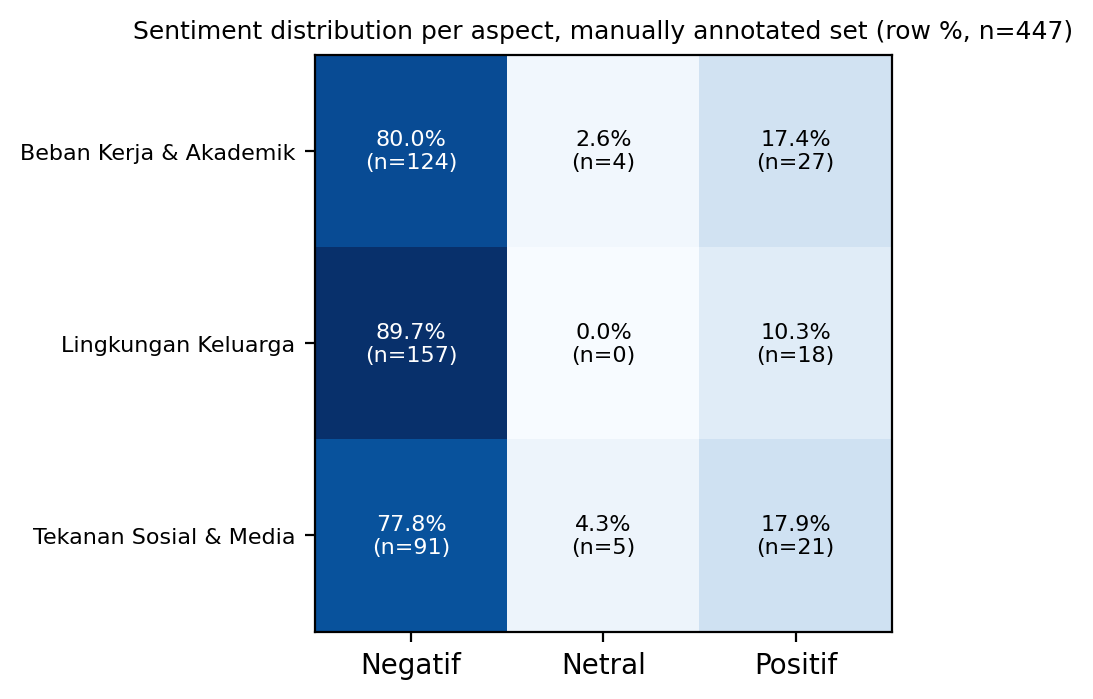

In [ ]:
# C.7 [BARU] Crosstab aspek x sentimen (menjawab: sentimen per aspek)
# Tabel utama memakai gold (label manusia) karena label otomatis sentimen tidak reliabel; versi seluruh data disimpan terpisah
pd.crosstab(df_final[aspek_col], df_final[sentimen_col]).to_csv(f"{RESULTS_DIR}/crosstab_aspek_sentimen_semua_label_otomatis.csv")
gold_all = df_final[(df_final["aspek_sumber"] == "gold") & (df_final["sentimen_sumber"] == "gold")]
print(f"Crosstab dihitung dari gold set (n={len(gold_all)}), bukan dari seluruh data.")
ct = pd.crosstab(gold_all[aspek_col], gold_all[sentimen_col])
ct_pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
print("Jumlah komentar:\n", ct, "\n\nPersen per baris (aspek):\n", ct_pct)
ct.to_csv(f"{RESULTS_DIR}/crosstab_aspek_sentimen_jumlah.csv")
ct_pct.to_csv(f"{RESULTS_DIR}/crosstab_aspek_sentimen_persen.csv")

fig, ax = plt.subplots(figsize=(6, 3.6), dpi=200)
ax.imshow(ct_pct.values, cmap="Blues")
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels([i.replace("Aspek ", "") for i in ct.index], fontsize=8)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct_pct.values[i, j]:.1f}%\n(n={ct.values[i, j]})", ha="center", va="center", fontsize=8,
                color="white" if ct_pct.values[i, j] > ct_pct.values.max() / 2 else "black")
ax.set_title(f"Sentiment distribution per aspect, manually annotated set (row %, n={len(gold_all)})", fontsize=9)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/heatmap_aspek_sentimen.png", bbox_inches="tight"); plt.show()

**SHAP**

In [ ]:
import shap
from transformers import pipeline as hf_pipeline
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

SHAP_DIR = f"{RESULTS_DIR}/shap"
os.makedirs(SHAP_DIR, exist_ok=True)


EXTRA_EN = {"don", "didn", "doesn", "isn", "aren", "wasn", "weren", "won", "wouldn", "couldn", "shouldn",
            "hasn", "haven", "hadn", "ain", "sub"}   


def valid_token(t):
    if not t.isalpha() or len(t) < 3:
        return False
    if FILTER_ENGLISH and (t in ENGLISH_STOP_WORDS or t in EXTRA_EN):
        return False
    return True


def aggregate_shap(records, idxs=None, min_freq=MIN_TOKEN_FREQ):
    rows = []
    sel = range(len(records)) if idxs is None else idxs
    for i in sel:
        rec = records[i]
        ci = rec["names"].index(rec["pred"])
        agg = collections.defaultdict(float)
        for tk, v in zip(rec["exp"].data, rec["exp"].values[:, ci]):
            tk = str(tk).strip().lower()
            if valid_token(tk):
                agg[tk] += float(v)
        rows += [(rec["pred"], tk, v, i) for tk, v in agg.items()]
    d = pd.DataFrame(rows, columns=["kelas", "token", "shap", "doc"])
    g = d.groupby(["kelas", "token"]).agg(
        n_doc=("doc", "nunique"), mean_shap=("shap", "mean"),
        mean_abs_shap=("shap", lambda x: np.abs(x).mean())).reset_index()
    return g[g["n_doc"] >= min_freq].sort_values(["kelas", "mean_abs_shap"], ascending=[True, False])


def plot_top_tokens(tok_df, task, path, top_n=15):
    classes = sorted(tok_df["kelas"].unique())
    fig, axes = plt.subplots(1, len(classes), figsize=(5.5 * len(classes), 5), dpi=200)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, classes):
        d = tok_df[tok_df["kelas"] == c].nlargest(top_n, "mean_abs_shap").iloc[::-1]
        ax.barh(d["token"], d["mean_abs_shap"], color=np.where(d["mean_shap"] >= 0, "#d62728", "#1f77b4"))
        ax.set_title(c.replace("Aspek ", ""), fontsize=10)
        ax.set_xlabel("mean |SHAP|")
    fig.suptitle(f"Top tokens by mean |SHAP| per predicted class ({task} task). "
                 f"Red: pushes toward the predicted class; blue: pushes away.", fontsize=10)
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.close(fig)


for task in TASKS:
    save_path = f"indobert_{task}_finetuned"
    if not os.path.isdir(save_path):
        print(f"Model {save_path} tidak ditemukan; jalankan C.4 dulu.")
        continue
    print(f"\n===== SHAP task {task.upper()} =====")
    pipe = hf_pipeline("text-classification", model=save_path, tokenizer=save_path,
                       device=0 if DEVICE == "cuda" else -1, top_k=None, truncation=True)
    explainer = shap.Explainer(pipe)

    # prediksi seluruh test set -> pilih sampel acak per kelas prediksi
    shap_pool = pd.concat([val_df, test_df], ignore_index=True)
    src_col = f"{task}_metode" if f"{task}_metode" in shap_pool.columns else f"{task}_sumber"
    texts_all = shap_pool[TEXT_COL].tolist()
    out = pipe(texts_all, batch_size=32)
    pred_lab = [max(o, key=lambda d: d["score"])["label"] for o in out]
    tp = pd.DataFrame({"text": texts_all, "true": shap_pool[TASKS[task]].values, "pred": pred_lab,
                       "src": shap_pool[src_col].values})
    sample = pd.concat([g.sample(n=min(N_SHAP_PER_CLASS, len(g)), random_state=SEED)
                        for _, g in tp.groupby("pred")]).reset_index(drop=True)
    print("Sampel SHAP per kelas prediksi:", sample["pred"].value_counts().to_dict())

    records = []
    chunk = 25
    for s in range(0, len(sample), chunk):
        part = sample.iloc[s:s + chunk]
        sv = explainer(part["text"].tolist())
        names = getattr(sv, "output_names", None)
        names = list(names) if names is not None else label_maps[task]["label_list"]
        for j, (_, r) in enumerate(part.iterrows()):
            records.append({"exp": sv[j], "names": names, "pred": r["pred"], "true": r["true"], "src": r["src"], "text": r["text"]})
        print(f"  {min(s + chunk, len(sample))}/{len(sample)} komentar selesai")

    tok_df = aggregate_shap(records)
    tok_df.to_csv(f"{SHAP_DIR}/shap_token_importance_{task}.csv", index=False)
    plot_top_tokens(tok_df, task, f"{SHAP_DIR}/shap_top_tokens_{task}.png")
    print(tok_df.groupby("kelas").head(10).to_string(index=False))

    # contoh lokal: prediksi benar dan salah
    ok_idx = [i for i, r in enumerate(records) if r["pred"] == r["true"]][:3]
    bad_idx = [i for i, r in enumerate(records) if r["pred"] != r["true"]][:3]
    for tag, idxs in [("benar", ok_idx), ("salah", bad_idx)]:
        for k, i in enumerate(idxs):
            try:
                html = shap.plots.text(records[i]["exp"], display=False)
                with open(f"{SHAP_DIR}/shap_contoh_{task}_{tag}_{k + 1}.html", "w", encoding="utf-8") as f:
                    f.write(html)
            except Exception as e:
                print("Lewati contoh", tag, k, e)

    # pemeriksaan  (aspek): apakah token penting berbeda untuk label rule-based vs zero-shot?
    if task == "aspek":
        for src in ["rule_based", "zero_shot"]:
            idxs = [i for i, r in enumerate(records) if r["src"] == src]
            if len(idxs) >= 30:
                t = aggregate_shap(records, idxs, min_freq=3)
                t.to_csv(f"{SHAP_DIR}/shap_token_importance_aspek_{src}.csv", index=False)
                print(f"\nTop token aspek untuk label {src} (n={len(idxs)}):")
                print(t.groupby("kelas").head(8).to_string(index=False))
            else:
                print(f"Sumber {src}: hanya {len(idxs)} komentar di sampel, dilewati.")

    del explainer, pipe
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


===== SHAP task ASPEK =====


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Sampel SHAP per kelas prediksi: {'Aspek Beban Kerja & Akademik': 100, 'Aspek Lingkungan Keluarga': 100, 'Aspek Tekanan Sosial & Media': 100}


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
PartitionExplainer explainer: 26it [01:17,  3.37s/it]


  25/300 komentar selesai


...

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 26it [01:17,  3.54s/it]


  175/186 komentar selesai


PartitionExplainer explainer: 12it [00:34,  4.35s/it]


  186/186 komentar selesai
  kelas    token  n_doc  mean_shap  mean_abs_shap
Negatif   nangis      8   0.237520       0.237520
Negatif    lelah      6   0.174515       0.174515
Negatif     mulu      5   0.154673       0.154673
Negatif   banget      9   0.091188       0.091188
Negatif    tidak     23   0.089156       0.089156
Negatif     gitu      6   0.086629       0.086629
Negatif   karena      7   0.086151       0.086151
Negatif     saja     10   0.085450       0.085450
Negatif    sudah     16   0.082604       0.082604
Negatif      klo      5   0.070811       0.070811
 Netral   gimana      7   0.559113       0.559113
 Netral      nya      5  -0.054206       0.054206
Positif semangat     14   0.618152       0.618152
Positif     baik     18   0.583712       0.583712
Positif  bahagia      6   0.485288       0.485288
Positif   sangat      7   0.216665       0.216665
Positif    kasih      6   0.093599       0.093599
Positif   semoga      6   0.078663       0.078663
Positif   cerita      6

**Results (ZIP)**

In [ ]:
with zipfile.ZipFile("hasil_revisi.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(RESULTS_DIR):
        for fn in fs:
            z.write(os.path.join(root, fn))
print("Terkemas: hasil_revisi.zip (berisi tabel metrik, confusion matrix, SHAP, statistik; TANPA model)")
files.download("hasil_revisi.zip")

Terkemas: hasil_revisi.zip (berisi tabel metrik, confusion matrix, SHAP, statistik; TANPA model)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>